# A/B compartments from chromatin tracing

This tutorial calls A/B compartments from traces with
`uchrom.strc.comp.call_compartments_axes_pc` (also `uc.tl.call_compartments`),
an independent implementation of ArcFISH's `ABCaller.by_axes_pc` (Yu et al.
2025, bioRxiv 10.1101/2025.11.26.690837).  You will call compartments along
a whole chromosome arm, name A and B with an annotation, validate the call
against Hi-C of the same loci (`call_compartments_hic`,
`compare_compartments`, `uchrom.pl.plot_compartments`), see how many traces
it needs, and run it on many chromosomes at once.  Data, both as a
`ChromData` from `ds.load`: Su et al. 2020 (*Cell* 182:1641) IMR90 chr21 —
651 loci of 50 kb over 10.4–46.7 Mb, 7,591 chromosome copies — with the
authors' Rao et al. 2014 IMR90 Hi-C summed into the same loci and linked as
a cooler (`"su2020_chr21"`: the first call downloads both tables once from
Zenodo 3928890, 262 MB, and builds the dataset in the data directory); and
Takei et al. 2021 (*Nature* 590:344) mESC at 25 kb (`"takei2021_mesc"`: the
FOF-CT core table `4DNFIHF3JCBY`, 22 MB, and its cell and RNA tables from
4DN).  Runtime: 2–4 minutes.

**How the caller works** (per chromosome):

1. The per-axis, distance-normalised variance matrix of the loop / TAD
   callers (`uchrom.fea.arc`) becomes a pseudo-contact matrix
   `K = exp(-var)` for each axis.
2. The eigenvector of the **second**-largest eigenvalue of each `K`
   carries the compartment alternation (the first follows the overall
   distance trend).
3. The three per-axis vectors, sign-aligned and weighted by the inverse
   per-axis measurement noise, are the features of a `KMeans(2)`; runs
   shorter than `min_bins` are merged into their neighbour.
4. A cluster is named `"A"`: by default the one with the smaller mean
   normalised variance (the more compact one), or the cluster given as
   `CompartmentCallerParams(a_cluster=...)`.  The `pc2` column is the
   summed feature track, positive for `"A"`.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import uchrom as uc
import uchrom.datasets as ds

plt.rcParams["figure.dpi"] = 90

OUT = Path("_out"); OUT.mkdir(exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)

## Load Su et al. 2020 chr21

`ds.load("su2020_chr21")` gives one trace per imaged chromosome copy (x / y
/ z in µm; loci not detected in a copy are left out), the number of genes
the authors list for each locus — the genes whose nascent transcription
they imaged, a simple marker of active (A) chromatin — as the bin track
`n_genes`, and their binned Hi-C as a cooler linked under the key
`"rao2014"` (read with `uchrom.io.read_su2020_tracing` /
`read_su2020_hic`, written with `uchrom.io.write_locus_cool`).

In [2]:
su = ds.load("su2020_chr21")
print(f"{su.n_traces} chromosome copies, {su.n_bins} loci, "
      f"{1 - su.n_spots / (su.n_traces * su.n_bins):.1%} of the locus positions not detected")

7591 chromosome copies, 651 loci, 6.5% of the locus positions not detected


In [3]:
su

ChromData: n_spots=4622909, n_traces=7591, n_bins=651
  spots:   ['chrom', 'start', 'end', 'trace_id', 'bin_id']
  tracks (bins):  ['n_genes']
  uns:     ['genome_assembly', 'xyz_unit', 'source', 'linked_cool', 'dataset']

## Call compartments

One call, every locus labelled.  The per-locus table is stored under
`"compartments.axes_pc"` in `cd.results`; the runs of equal label become a
`segment` interval table in `cd.intervals`, and the `pc2` track is written
to `cd.bin_tracks`.

In [4]:
from uchrom.strc.comp import CompartmentCallerParams

t0 = time.perf_counter()
comp = uc.tl.call_compartments(su, verbose=True)
print(f"{time.perf_counter() - t0:.0f} s")
print(comp.compartment.value_counts().to_dict())
print(su.intervals)
print("bin tracks:", list(su.bin_tracks.columns))
comp.head()

[comp/chr21] variance cube + normalise...


[comp/chr21] axis weights: [0.237 0.246 0.517]
[comp/chr21] KMeans on 651 bins × 3 features


48 s
{'A': 373, 'B': 278}
IntervalStore({'compartments.axes_pc': <segment, 20 rows>})
bin tracks: ['n_genes', 'compartments.axes_pc.pc2']


,chrom,start,end,bin_index,cluster,compartment,pc2
0,chr21,10400000,10450000,0,1,A,-0.004721
1,chr21,10500000,10550000,1,1,A,0.002982
2,chr21,10600000,10650000,2,1,A,0.002798
3,chr21,13250000,13300000,3,1,A,0.018045
4,chr21,14000000,14050000,4,1,A,0.004141


## Naming A and B

KMeans only separates two groups; which one is A needs biology.  The
default rule calls the more compact cluster A.  Compare the labels with the
gene annotation (the segments mapped back onto the loci):

In [5]:
labels = su.intervals["compartments.axes_pc"].to_bins(su.bins, column="label")      # per locus
su.bin_tracks.groupby(labels)["n_genes"].agg(loci="size", genes_per_locus="mean")

,loci,genes_per_locus
label,,
A,373,0.050938
B,278,0.233813


Here the **more compact** cluster is the gene-poor one — as expected for B
(heterochromatin is the more compact compartment in imaging data), so the
compaction rule names the compartments the wrong way round on these data.
`CompartmentCallerParams(a_track="n_genes")` names A with the annotation
instead: the cluster whose loci have more genes on average.  Call again
(the clustering is deterministic, `random_state=0`); the stored result is
replaced.

In [6]:
NAMED = CompartmentCallerParams(a_track="n_genes")
comp = uc.tl.call_compartments(su, params=NAMED)
seg = su.intervals["compartments.axes_pc"]
print(comp.compartment.value_counts().to_dict(), "|", len(seg), "segments,",
      f"median length {seg.eval('end - start').median() / 1e6:.1f} Mb")
seg.head()

{'B': 373, 'A': 278} | 20 segments, median length 0.6 Mb


,chrom,start,end,label,n_bins,pc2
0,chr21,10400000,14850000,B,21,-0.010437
1,chr21,14850000,15050000,A,4,0.014067
2,chr21,15050000,15650000,B,12,-0.005133
3,chr21,15650000,15900000,A,5,0.014856
4,chr21,15900000,16000000,B,2,0.004568


## Validate against Hi-C of the same loci

The classic Hi-C compartment track is the first principal component of the
correlation matrix of the observed / expected contact map.
`call_compartments_hic` computes it on the linked cooler: the loci are not
evenly spaced, so the expected count is taken per class of genomic
separation (log-spaced), and `orient_by="n_genes"` orients PC1 so that
gene-rich loci are positive.  `compare_compartments` then matches the two
calls locus by locus.

In [7]:
from uchrom.strc.comp import call_compartments_hic, compare_compartments

hic = call_compartments_hic(su, contacts="rao2014", orient_by="n_genes")     # key "compartments.hic_pc1"
agree = compare_compartments(su, "compartments.axes_pc", "compartments.hic_pc1")
print(f"imaging vs Hi-C: {agree['agreement']:.1%} of {agree['n_bins']} loci get the same label; "
      f"r(pc2, Hi-C PC1) = {agree['pearson_r']:.2f}")

imaging vs Hi-C: 90.9% of 651 loci get the same label; r(pc2, Hi-C PC1) = 0.92


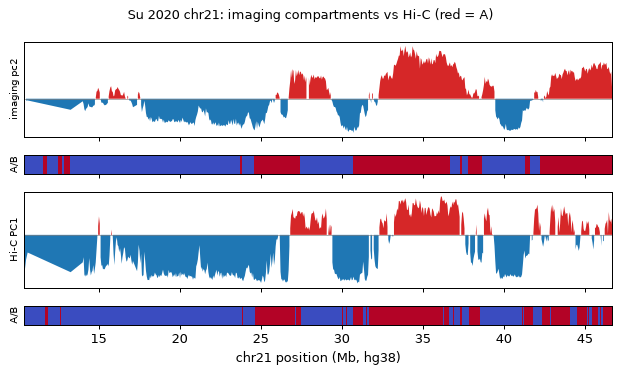

In [8]:
from uchrom.pl import plot_compartments

fig = plot_compartments(su, ["compartments.axes_pc", "compartments.hic_pc1"], names=["imaging pc2", "Hi-C PC1"])
fig.axes[-1].set_xlabel("chr21 position (Mb, hg38)")
fig.suptitle("Su 2020 chr21: imaging compartments vs Hi-C (red = A)", fontsize=10)
plt.tight_layout(); plt.show()

**How this compares with the paper.**  ArcFISH validated this caller on Su
2020 chromosome 2 (250 kb, 3,029 traces), where 84.3 % of the loci share the
bulk Hi-C assignment.  On chromosome 21 this implementation agrees with
the Hi-C compartments at a similar level (the number above), and its track
follows Hi-C PC1 closely.

## How many traces are needed?

ArcFISH reports that about 30 traces are enough to assign A/B
compartments.  `trace_ids=` restricts the call to a random subset of
chromosome copies; A is named with the gene annotation as above, and each
call is compared with the Hi-C compartments.

In [9]:
rng = np.random.default_rng(0)
copies = su.spots["trace_id"].astype(str).unique()
rows = []
for n in (30, 100, 300):
    for rep in range(2):
        pick = rng.choice(copies, size=n, replace=False)
        c = uc.tl.call_compartments(su, trace_ids=pick, params=NAMED, key_added=None)
        s = compare_compartments(su, c, "compartments.hic_pc1")
        rows.append({"traces": n, "draw": rep, "same label as Hi-C": s["agreement"],
                     "r(pc2, Hi-C PC1)": s["pearson_r"]})
pd.DataFrame(rows).round(3)

,traces,draw,same label as Hi-C,"r(pc2, Hi-C PC1)"
0,30,0,0.912,0.843
1,30,1,0.865,0.827
2,100,0,0.908,0.914
3,100,1,0.916,0.916
4,300,0,0.911,0.921
5,300,1,0.914,0.913


## Many chromosomes at once (Takei 2021)

With `chrom=None` (the default) the caller runs each chromosome and merges
the tables.  The Takei 2021 25-kb data have one region of 60 loci per
chromosome (1.5–2.4 Mb) — no longer than a typical compartment, so the two
clusters found inside each region are sub-region structure rather than
genome-wide A/B; the example shows the mechanics and the outputs.

In [10]:
cd = ds.load("takei2021_mesc")
comps = uc.tl.call_compartments(cd)
seg = cd.intervals["compartments.axes_pc"]
print(f"{len(comps)} loci on {comps.chrom.nunique()} chromosomes -> {len(seg)} segments")

# interval tables map back onto any bin table: label of the overlapping segment per locus
labels = seg.to_bins(cd.bins, how="id", column="label")
print(labels.value_counts().to_dict())
cd.bins.assign(label=labels, pc2=cd.bin_tracks["compartments.axes_pc.pc2"]).head()

1200 loci on 20 chromosomes -> 57 segments
{'B': 676, 'A': 524}


,chrom,start,end,label,pc2
bin_id,,,,,
0,chr1,135600000,135625000,A,0.059432
1,chr1,135625000,135650000,A,0.049659
2,chr1,135650000,135675000,A,0.013774
3,chr1,135675000,135700000,A,0.069936
4,chr1,135700000,135725000,A,0.073225


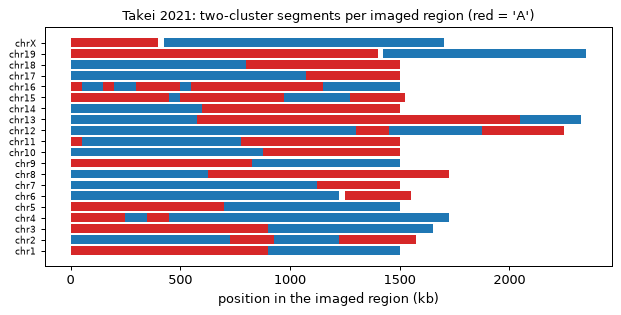

In [11]:
from uchrom.io import sort_chroms

fig, ax = plt.subplots(figsize=(7, 3.6))
order = sort_chroms(seg.chrom)                    # chr1, chr2, ..., chr19, chrX
for y, chrom in enumerate(order):
    g = seg[seg.chrom == chrom]
    lo = cd.bins.loc[cd.bins.chrom == chrom, "start"].min()
    ax.broken_barh(list(zip((g.start - lo) / 1e3, (g.end - g.start) / 1e3)), (y - 0.4, 0.8),
                   facecolors=["tab:red" if l == "A" else "tab:blue" for l in g.label])
ax.set_yticks(range(len(order)), order, fontsize=7)
ax.set_xlabel("position in the imaged region (kb)")
ax.set_title("Takei 2021: two-cluster segments per imaged region (red = 'A')", fontsize=10)
plt.tight_layout(); plt.show()

## Notes

- Name A / B with biology (gene density, active histone marks, Hi-C):
  `CompartmentCallerParams(a_track=...)` takes a bin track, `a_cluster=` a
  cluster label; the default compaction rule is a convention and named the
  compartments the wrong way round on Su 2020 chr21.
- `n_clusters > 2` explores sub-compartments; the labels are then
  `"A"` for the A cluster and `"B"` for every other cluster, so use the
  `cluster` column.
- `call_compartments_hic` works on any linked `.cool` / `.mcool`
  (`resolution=` for the latter; `HiCCompartmentParams(balance=True)` for the
  ICE-balanced map); `compare_compartments` compares any two per-bin calls
  on the loci of a `ChromData`.
- On a backed store the caller reads one chromosome at a time
  (`get_chrom`); it has no streaming mode — the loop and TAD callers do.
- `uchrom.strc.enrichment.add_structural_features` projects the stored
  compartments (label, `pc2`) onto bins together with TADs and loops (see
  `tad_calling`).

## Next steps

- `tad_calling` — TADs on the same chr21 loci, imaging vs Hi-C, and the
  backed / streaming workflow.
- `loop_calling` — loops on the Takei 2021 data.